# First cosmological analysis: inferring ($\sigma_8, b_g$) from galaxy auto and galaxy x cmb lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/test_box_x/results/`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/test_box_x/results/`.
    - The galaxies auto-spectrum $C_{\ell}^{gg}$ and kappa $\times$ galaxies cross-spectrum $C_{\ell}^{\kappa g}$ can be found in `./data/test_box_x/cls/` with the corresponding errorbars, and a logarithmic binning run with `./scripts/generate_binned_cls.py`.
- The notebook also fits for two parameters in the modelling accounting for a rescaling of the theory bias.

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp

from scipy.optimize import minimize, minimize_scalar
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus
from getdist import MCSamples, plots

import os
import json
import re
import sys
sys.path.append('../')

from utils.binning import make_hybrid_bin_matrix

# Functions

## theory

In [44]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [45]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2 - cosmo_dict.get("mnu", 0.06) / 93.14  # subtract neutrino contribution to omega_cdm
    mnu = cosmo_dict.get("mnu", 0.06)
    omk = cosmo_dict.get("omk", 0.0)

    # Initial CAMB params

    pars = camb.CAMBparams()
    
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
        mnu=mnu,
        omk=omk,
    )

    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings
    pars.WantTransfer = True
    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax,
        nonlinear=nonlinear
    )

    # Final results
    results = camb.get_results(pars)

    return results

In [46]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel Wg(chi(z)).
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz_grid"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]

    bias = bz_interp(z)
    bias = np.where(np.isnan(bias), 0, bias)  # set nan bias to zero
    ndensity = nz_interp(z)
    ndensity = np.where(np.isnan(ndensity), 0, ndensity)  # set nan density to zero

    return bias * ndensity * (Hz / c_kms)

In [47]:
def W_kappa(z, kernel_context):
    '''
    CMB lensing convergence kernel Wk(chi(z)).
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi_grid"]
    chi_source = kernel_context["chi_source"]
    Hz = kernel_context["Hz_grid"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

## data

In [48]:
def get_colore_cls(box_filename, cmb_lensing=False):
    '''
    Load Colore power spectrums from .npz files
    '''

    data = np.load(box_filename)

    if cmb_lensing:
        return data['ells'], data['cls'], data['err'], data['nside']
    else:
        return data['ells'], data['cls'], data['err'], data['nside'], data['shot_noise']

In [49]:
def get_ensemble_cls(boxes, galaxy_catalog_bin, cls_type='gg'):
    '''
    Load CoLoRe power spectrums from .npz files and average the ensemble
    '''

    cls = []
    var = []
    nside = []
    shot_noise = []

    for box in boxes:
        if cls_type not in ['gg', 'kg', 'kk']:
            raise ValueError(f"Invalid cls_type: {cls_type}. Must be one of ['gg', 'kg', 'kk'].")

        if cls_type == 'kk':
            box_path = f'../data/ensembles/{box}/cls/cl_{cls_type}.npz'
        else:
            box_path = f'../data/ensembles/{box}/cls/cl_{cls_type}_{galaxy_catalog_bin}.npz'
        data = np.load(box_path)

        ells = data['ells']
        cls.append(data['cls'])
        var.append(data['err']**2)  # store variance instead of error
        nside.append(data['nside'])

        if not cls_type == 'kk':
            shot_noise.append(data['shot_noise'])

    scatter = np.var(np.array([B_data @ cls for cls in cls]), axis=0, ddof=1)  # calculate variance across boxes
    
    cls = np.mean(cls, axis=0)
    var = np.mean(var, axis=0)
    nside = np.mean(nside, axis=0, dtype=int)
    shot_noise = np.mean(shot_noise, axis=0)

    if cls_type == 'kk':
        return ells, cls, var, nside, scatter
    else:
        return ells, cls, var, nside, shot_noise, scatter

In [50]:
def build_theory_cov(Abias, A_sn, cls_gg_lin_full, cls_kg_lin_full, cls_kk_lin_full, ells, shot_noise, pw_gg, pw_kg, Bcov, fit_mask, fsky=1.0, binned=False):
    '''
    Build the theory covariance matrix for the galaxy-galaxy and galaxy-kappa power spectra.
    '''
    cls_gg = (Abias**2 * cls_gg_lin_full + A_sn * shot_noise + shot_noise) * pw_gg**2   # (signal + residual + Poisson) * pixel window function
    cls_kg = (Abias * cls_kg_lin_full) * pw_kg
    var_gg = 2 * cls_gg**2 / ((2*ells + 1) * fsky)
    var_kg = (cls_kg**2 + cls_kk_lin_full * cls_gg) / ((2*ells + 1) * fsky)
    xcov   = 2 * cls_kg * cls_gg / ((2*ells + 1) * fsky)

    cov_gg = (Bcov @ np.diag(var_gg) @ Bcov.T)/len(boxes)  # scale by number of boxes to get the covariance of the mean
    cov_kg = (Bcov @ np.diag(var_kg) @ Bcov.T)/len(boxes)  # scale by number of boxes to get the covariance of the mean
    xcov_mat   = (Bcov @ np.diag(xcov) @ Bcov.T)/len(boxes)  # scale by number of boxes to get the covariance of the mean
    cov_gg_fit = cov_gg[np.ix_(fit_mask, fit_mask)]
    cov_kg_fit = cov_kg[np.ix_(fit_mask, fit_mask)]
    xcov_fit   = xcov_mat[np.ix_(fit_mask, fit_mask)]

    cov_fit = np.block([
    [cov_gg_fit, xcov_fit],
    [xcov_fit.T, cov_kg_fit],
    ])

    if binned:
        return cov_fit, cov_gg_fit, cov_kg_fit, cov_gg, cov_kg
    else:
        return cov_fit, cov_gg_fit, cov_kg_fit

In [51]:
def build_theory_cov_kk(cls_kk_lin_full, ells, Bcov, fit_mask, fsky=1.0, binned=False):
    '''
    Build the theory covariance matrix for the kappa-kappa power spectrum.
    '''
    var_kk = 2 * cls_kk_lin_full**2 / ((2*ells + 1) * fsky)
    cov_kk = (Bcov @ np.diag(var_kk) @ Bcov.T)/len(boxes)  # scale by number of boxes to get the covariance of the mean
    cov_kk_fit = cov_kk[np.ix_(fit_mask, fit_mask)]

    if binned:
        return cov_kk_fit, cov_kk
    else:
        return cov_kk_fit


## fitting

In [52]:
def get_limber_cls_fit(
    theta,
    cls_theory_input,
    sigma8_fid,
    shot_noise,
):
    '''
    Compute the angular gg and kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8, A_sn = theta

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_gg_theory = (Abias**2 * growth_factor * cls_theory_input[0]) + (A_sn * shot_noise)
    cls_kg_theory = Abias * growth_factor * cls_theory_input[1]

    return cls_gg_theory, cls_kg_theory

In [53]:
def get_limber_cls_fit_gg(
    theta,
    cls_gg_theory_input,
    sigma8_fid,
    shot_noise
):
    '''
    Compute the angular gg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8, A_sn = theta

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_gg_theory = Abias**2 * growth_factor * cls_gg_theory_input + (A_sn * shot_noise)

    return cls_gg_theory

In [54]:
def get_limber_cls_fit_kg(
    theta,
    cls_kg_theory_input,
    sigma8_fid,
    _,
):
    '''
    Compute the angular kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = theta

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_kg_theory = cls_kg_theory_input * Abias * growth_factor

    return cls_kg_theory

In [55]:
def get_limber_cls_fit_kk(
    theta,
    cls_kk_theory_input,
    sigma8_fid,
    _,
):
    '''
    Compute the angular kk power spectra using the Limber approximation.
    '''

    # fitting parameters
    sigma8 = theta

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_kk_theory = cls_kk_theory_input * growth_factor

    return cls_kk_theory

In [56]:
def get_limber_cls_fit_kk_kp(
    theta,
    simpson_weights,
    base_kk_theory_input,
    kgrid,
    sigma8_fid,
):
    '''
    Compute the angular kk power spectra using the Limber approximation.
    '''

    # fitting parameters
    sigma8, kp = theta

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2
    smooth = np.exp(-(kgrid/kp)**2)

    cls_kk_theory = growth_factor * simpson_weights @ (base_kk_theory_input * smooth) 

    return cls_kk_theory

In [57]:
def get_limber_cls_fit_kk_kp_only(
    theta,
    simpson_weights,
    base_kk_theory_input,
    kgrid,
    sigma8_fid
):
    '''
    Compute the angular kk power spectra using the Limber approximation.
    '''

    # fitting parameters
    kp = theta

    # sigma8 amplitude
    smooth = np.exp(-(kgrid/kp)**2)

    cls_kk_theory = simpson_weights @ (base_kk_theory_input * smooth) 

    return cls_kk_theory

In [58]:
def get_chi2(
    theta,  
    cls_theory_input,
    B_gg,
    B_kg,
    mask_fit,
    cls_data_binned,
    invcov_mat,
    sigma8_fid,
    shot_noise,
):
    '''
    Reduced chi-squared for joint gg and kg fitting.
    '''

    # compute theory
    cls_gg_theory_unbinned, cls_kg_theory_unbinned = get_limber_cls_fit(
        theta,
        cls_theory_input,
        sigma8_fid,
        shot_noise,
    )

    # bin the theory to match the data
    cls_gg_binned = B_gg @ cls_gg_theory_unbinned
    cls_kg_binned = B_kg @ cls_kg_theory_unbinned

    # create theory vector
    cls_theory_binned = np.concatenate((cls_gg_binned[mask_fit], cls_kg_binned[mask_fit]))

    # residual
    residual = cls_data_binned - cls_theory_binned

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T
    
    return chi2

In [59]:
def get_chi2_single(
    theta,
    get_limber_cls_fit_single,
    cls_theory_input,
    B,
    mask_fit,
    cls_data_binned,
    invcov_mat,
    sigma8_fid,
    shot_noise
):
    '''
    Reduced chi-squared for gg, kg and kk fitting.
    '''

    # compute theory
    cls_theory_unbinned = get_limber_cls_fit_single(
        theta,
        cls_theory_input,
        sigma8_fid,
        shot_noise
    )
    
    # bin the theory to match the data
    cls_theory_binned = B @ cls_theory_unbinned

    # residual
    residual = cls_data_binned - cls_theory_binned[mask_fit]

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T

    return chi2

In [60]:
def get_chi2_single_kp(
    theta,
    get_limber_cls_fit_single,
    simpsons_weights,
    base_theory_input,
    kgrid,
    B,
    mask_fit,
    cls_data_binned,
    invcov_mat,
    sigma8_fid,
):
    '''
    Reduced chi-squared for kk fitting with varying kp parameter.
    '''

    # compute theory
    cls_theory_unbinned = get_limber_cls_fit_single(
        theta,
        simpsons_weights,
        base_theory_input,
        kgrid,
        sigma8_fid,
    )
    
    # bin the theory to match the data
    cls_theory_binned = B @ cls_theory_unbinned

    # residual
    residual = cls_data_binned - cls_theory_binned[mask_fit]

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T

    return chi2

## sampler

In [61]:
def log_prior(theta):
    '''
    Flat priors on A_bias and sigma8.
    '''

    Abias, sigma8, A_sn = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5 and -5.0 < A_sn < 100.0:
        return 0.0

    return -np.inf

In [62]:
def log_prior_single(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    if len(theta) == 3:
        Abias, sigma8, A_sn = theta

        if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5 and -5.0 < A_sn < 100.0:
            return 0.0

        return -np.inf

    if len(theta) == 2:
        Abias, sigma8 = theta

        if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
            return 0.0

        return -np.inf
    
    if len(theta) == 1:
        sigma8 = theta

        if 0.5 < sigma8 < 1.5:
            return 0.0

        return -np.inf

In [63]:
def log_posterior(
    theta,
    cls_theory_input,
    B_gg,
    B_kg,
    mask_fit,
    cls_data,
    invcov_mat,
    sigma8_fid,
    shot_noise
):
    '''
    Log-posterior for the joint gg and kg fitting.
    '''

    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2(
        theta,
        cls_theory_input,
        B_gg,
        B_kg,
        mask_fit,
        cls_data,
        invcov_mat,
        sigma8_fid,
        shot_noise
    )

    return lp - 0.5 * chi2

In [64]:
def log_posterior_single(
    theta,
    get_limber_cls_fit_single,
    cls_theory_input,
    B,
    mask_fit,
    cls_data,
    invcov_mat,
    sigma8_fid,
    shot_noise
):
    '''
    Log-posterior for the gg, kg and kk fitting.
    '''

    lp = log_prior_single(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2_single(
        theta,
        get_limber_cls_fit_single,
        cls_theory_input,
        B,
        mask_fit,
        cls_data,
        invcov_mat,
        sigma8_fid,
        shot_noise
    )

    return lp - 0.5 * chi2

## plotting

In [65]:
def format_catalog_name(cat_str):
    # Remove '_gal_' tags
    clean = re.sub(r'_gal_', ' ', cat_str, flags=re.IGNORECASE)
    # Format 'bin0' or 'bin_0' -> 'Bin 0'
    clean = re.sub(r'bin_?(\d+)', r'Bin \1', clean, flags=re.IGNORECASE)
    
    # Capitalize 'Bin' and set acronyms/surveys (LSST, DESI, QSO) to uppercase
    parts = clean.replace('_', ' ').split()
    formatted = [p.capitalize() if p.lower() == 'bin' else p.upper() for p in parts]
    return " ".join(formatted)

# Example usages:
# 'lsst_gal_bin0'  -> 'LSST Bin 0'
# 'desi_qso_bin0'  -> 'DESI QSO Bin 0'

In [66]:
def plot_cls_comparison(ells, cl_lin,
                        ells_sim_fit, cl_sim_fit, err_sim_fit, cl_lin_binned_fit,
                        lmin_fit, lmax_fit, nbins_fit, sigma8, Abias, Asn, 
                        box_label, plot_title='', test_name='', xx=''):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 5), height_ratios=[2.5, 1], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    # 1. Limber_linear handle
    h_lin, = ax1.plot(ells, cl_lin, c='C0', ls='-', label=rf'Limber_linear')

    # 2. Limber_linear-logbin handle
    h_bin = ax1.errorbar(ells_sim_fit, cl_lin_binned_fit, fmt='*', c='skyblue', ms=7.0, mec='k', mew=0.5, label='Limber_linear-logbin', zorder=9)

    # 3. CoLoRe box handle
    h_col = ax1.errorbar(ells_sim_fit, cl_sim_fit, yerr=err_sim_fit, fmt='k.', ms=5.0,
                         elinewidth=0.8, capsize=2.0, ecolor='k', label='CoLoRe '+box_label, zorder=10)
    
    # 4. Fitting multipoles handle
    h_fit = ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting multipoles')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_ylabel(rf'$C_{{L}}^{{{xx}}}$')

    # Pass handles in exact desired order (labels are extracted automatically)
    ax1.legend(handles=[h_lin, h_bin, h_col, h_fit], loc='lower left')

    ax1.grid(True, which='major', alpha=0.25)
    ax1.grid(True, which='minor', alpha=0.10)
    if xx == 'gg' or xx == 'kg':
        ax1.set_xlim(xmin=lmin_fit*0.9, xmax=ells_sim_fit[nbins_fit+3])
    elif xx == 'kk':
        ax1.set_xlim(xmin=lmin_fit*0.9, xmax=ells_sim_fit[nbins_fit-1]*1.1)
    ax1.set_ylim(ymin=cl_lin[lmax_fit-lmin_fit]*0.5, ymax=cl_sim_fit[0]*2.0)

    # Plotting the residuals
    pull = (cl_sim_fit - cl_lin_binned_fit) / err_sim_fit
    pull_max = np.max(np.abs(pull[:(nbins_fit+3)]))
    chi2_best = np.sum((pull[:(nbins_fit-1)])**2)

    # Joint best-fit parameters as text labels
    ax1.text(0.95, 0.81, rf'$(\sigma_8= {sigma8:.3f})$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
    if xx == 'kk':      # plotting cmb lensing auto cls
        reduced_chi2_best = chi2_best / (nbins_fit-1)
        ax1.text(0.95, 0.95, rf'$\chi^2_{{{xx}}}/ n_{{\text{{dof}}}} = {chi2_best:.0f}/{nbins_fit-1} = {reduced_chi2_best:.2f}$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
    elif xx == 'kg':  # plotting cmb lensing x galaxy cls
        reduced_chi2_best = chi2_best / (nbins_fit-2)
        ax1.text(0.95, 0.95, rf'$\chi^2_{{{xx}}}/ n_{{\text{{dof}}}} = {chi2_best:.0f}/{nbins_fit-2} = {reduced_chi2_best:.2f}$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
        ax1.text(0.95, 0.88, rf'$(A_{{bias}}= {Abias:.3f})$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
    elif xx == 'gg':  # plotting galaxy auto cls
        reduced_chi2_best = chi2_best / (nbins_fit-3)
        ax1.text(0.95, 0.95, rf'$\chi^2_{{{xx}}}/ n_{{\text{{dof}}}} = {chi2_best:.0f}/{nbins_fit-3} = {reduced_chi2_best:.2f}$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
        ax1.text(0.95, 0.88, rf'$(A_{{bias}}= {Abias:.3f})$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
        ax1.text(0.95, 0.74, rf'$(A_{{sn}}= {Asn:.3f})$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)


    ax2.errorbar(ells_sim_fit, pull, fmt='k.', ms=5.0, mec='k')
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.12)
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(rf'$\Delta C_L^{{{xx}}}/\sigma$')
    ax2.set_ylim(-pull_max - 1, pull_max + 1)
    ax2.grid(True, which='major', alpha=0.25)
    ax2.grid(True, which='minor', alpha=0.10)

    fig.suptitle(plot_title, y=1)
    fig.savefig(f'../data/{box_label}/plots/cls_{xx}_{box_label}_{test_name}.png', bbox_inches='tight')
    plt.show()

In [67]:
def plot_cls_comparison_kk_kp(ells, cl_lin,
                           ells_sim_fit, cl_sim_fit, err_sim_fit, cl_lin_binned_fit,
                           lmin_fit, lmax_fit, reduced_chi2_best, sigma8, kp_array,
                           box_label, plot_title='', test_name='', xx=''):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7), height_ratios=[2.5, 1.5], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    idx = np.abs(kp_array - kp).argmin()  # index of the kp value closest to 1.0 1/Mpc
    
    # 1. Capture handles for all Limber_linear curves
    h_lin_list = []
    for i in range(len(kp_array)):
        if i == idx:
            line, = ax1.plot(ells, cl_lin[i], ls='--', label=rf'$k_p={kp_array[i]:.3f} \ \text{{1/Mpc}} \ (\sigma_8={sigma8[i]:.3f}, \ \chi^2_\nu= {reduced_chi2_best[i]:.2f}$) - Fixed kp')
        elif i == len(kp_array)-1:
            line, = ax1.plot(ells, cl_lin[i], ls='-.', label=rf'$k_p={kp_array[i]:.3f} \ \text{{1/Mpc}} \ (\sigma_8={sigma8[i]:.3f}, \ \chi^2_\nu= {reduced_chi2_best[i]:.2f}$) - Best fit')
        else:
            line, = ax1.plot(ells, cl_lin[i], ls='-', label=rf'$k_p={kp_array[i]:.3f} \ \text{{1/Mpc}} \ (\sigma_8={sigma8[i]:.3f}, \ \chi^2_\nu= {reduced_chi2_best[i]:.2f}$)')
        h_lin_list.append(line)

    # 2. Capture handle for CoLoRe box
    h_col = ax1.errorbar(ells_sim_fit, cl_sim_fit, yerr=err_sim_fit, fmt='k.', ms=5.0,
                         elinewidth=0.8, capsize=2.0, ecolor='k', label='CoLoRe '+box_label, zorder=10)

    # 3. Capture handle for Fitting multipoles
    h_fit = ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting multipoles')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_ylabel(rf'$C_{{L}}^{{{xx}}}$')

    # Pass all captured handles in sequence
    ax1.legend(handles=[*h_lin_list, h_col, h_fit], loc='lower left', fontsize=8)

    ax1.grid(True, which='major', alpha=0.25)
    ax1.grid(True, which='minor', alpha=0.10)

    # Plot relative errors
    pull = [(cl_sim_fit - cl_lin_binned) / err_sim_fit for cl_lin_binned in cl_lin_binned_fit]
    pull_max = 25

    for i, p in enumerate(pull):
        if i == idx:
            ax2.errorbar(ells_sim_fit, p, fmt='*', ms=7.0, mec='k', mew=0.0)
        else:
            ax2.errorbar(ells_sim_fit, p, fmt='.', ms=5.0)
        
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.12)
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)

    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(rf'$\Delta C_L^{{{xx}}}/\sigma$')
    ax2.set_ylim(-pull_max - 1, pull_max + 1)
    ax2.tick_params(axis='y', which='minor', length=4, color='gray')

    ax2.grid(True, which='major', alpha=0.25)
    ax2.grid(True, which='minor', alpha=0.10)

    fig.suptitle(plot_title, y=0.95)
    fig.savefig(f'../data/{box_label}/plots/cls_{xx}_{box_label}_{test_name}.png', bbox_inches='tight')
    plt.show()

In [68]:
def plot_cls_comparison_kk_nside(ells, cl_lin,
                           ells_sim_fit, cl_sim_fit, err_sim_fit, cl_lin_binned_fit,
                           lmin_fit, lmax_fit, reduced_chi2_best, sigma8, labels,
                           box_label, plot_title='', test_name='', xx=''):

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(6, 7), height_ratios=[2.5, 1.5, 1], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    colors = ['C0', 'C1', 'C2']  # Extend as needed

    # 1. Capture handles for all Limber_linear curves
    h_lin_list = []
    for i in range(len(labels)):
        eb_container = ax1.errorbar(ells_sim_fit, cl_sim_fit[i], yerr=err_sim_fit[i], c=colors[i], fmt='.', ms=5.0,
                         elinewidth=0.8, capsize=2.0, label='CoLoRe box NSIDE='+labels[i], zorder=10, alpha=1.0)
        h_lin_list.append(eb_container)
        line, = ax1.plot(ells, cl_lin[i], ls='-', c=colors[i], label=rf'Theory fit $(\sigma_8={sigma8[i]:.3f}, \ \chi^2_\nu= {reduced_chi2_best[i]:.2f}$)', alpha=1.0)
        h_lin_list.append(line)

    # 2. Capture handle for Fitting multipoles
    h_fit = ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting multipoles')

    # Pass all captured handles in sequence
    ax1.legend(handles=[*h_lin_list, h_fit], loc='lower left', fontsize=8)

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_ylabel(rf'$C_{{L}}^{{{xx}}}$')

    ax1.grid(True, which='major', alpha=0.25)
    ax1.grid(True, which='minor', alpha=0.10)

    # Plot relative errors
    pull = [(cl_sim_fit - cl_lin_binned) / err_sim_fit for cl_sim_fit, cl_lin_binned, err_sim_fit in zip(cl_sim_fit, cl_lin_binned_fit, err_sim_fit)]
    pull_max = 20

    for i, p in enumerate(pull):
        ax2.errorbar(ells_sim_fit, p, c=colors[i], fmt='.', ms=5.0)
        
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.12)
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)

    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(rf'$\Delta C_L^{{{xx}}}/\sigma$')
    ax2.set_ylim(-pull_max - 1, pull_max + 1)
    ax2.tick_params(axis='y', which='minor', length=4, color='gray')

    ax2.grid(True, which='major', alpha=0.25)
    ax2.grid(True, which='minor', alpha=0.10)

    ax3.scatter(ells_sim_fit, (cl_sim_fit[0] - cl_sim_fit[2])/cl_sim_fit[2], c=colors[0], label='NSIDE='+labels[0], s=10)
    ax3.scatter(ells_sim_fit, (cl_sim_fit[1] - cl_sim_fit[2])/cl_sim_fit[2], c=colors[1], label='NSIDE='+labels[1], s=10)
    ax3.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.12)
    ax3.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)

    ax3.set_xlabel(r'Multipole $L$')
    ax3.set_ylabel(rf'$\Delta C_L^{{{xx}, NSIDE}}/C_L^{{{xx}, NSIDE:2048}}$')
    ax3.tick_params(axis='y', which='minor', length=4, color='gray')

    ax3.grid(True, which='major', alpha=0.25)
    ax3.grid(True, which='minor', alpha=0.10)

    fig.suptitle(plot_title, y=0.95)
    fig.savefig(f'../data/{box_label}/plots/cls_{xx}_{box_label}_{test_name}.png', bbox_inches='tight')
    plt.show()

# Selecting sample

## choosing data

In [69]:
# choose the box for which to compare the theory and the CoLoRe Cls
boxes = [f'ensemble_{i}' for i in range(1, 11)]  # ensemble_1, ensemble_2, ..., ensemble_10

galaxy_catalog = 'lsst_gal'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
galaxy_catalog_bin = f'{galaxy_catalog}_bin0'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'

params_path = [f'../data/ensembles/{box}/cosmo_params.json' for box in boxes]

In [70]:
cosmo_dict = load_cosmology(params_path[0])
z_max = cosmo_dict["z_max"]

## measure and compare output n(z) with input n(z)

In [71]:
# load the galaxy bias distribution and create interpolator
z_bz, bz = np.loadtxt(f'../data/colore_setup/inputs/bias/bz_{galaxy_catalog}.txt', unpack=True)
zbin_width_bz = np.diff(z_bz)[0]
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

zmean_array = []
nz_interp_output_bin = []
dz_array = []

for box in boxes:
    # load the bin output n(z) histogram output from colore
    nz_file_bin = np.load(f'../data/ensembles/{box}/cls/nz_{galaxy_catalog_bin}.npz')
    z_nz, nz = nz_file_bin['z_nz'], nz_file_bin['nz']
    zmean_array.append(nz_file_bin['z_mean'])
    dz_array.append(nz_file_bin['dz'])
    norm_array = simpson(nz, x=z_nz)
    nz_interp_output_bin.append(PchipInterpolator(z_nz, nz/norm_array, extrapolate=False))   

zmean = np.mean(zmean_array)
dz = np.mean(dz_array) 

# Ensemble analysis: ($\sigma_8$, $b_g$, $A_{sn}$) fit

The plan is to infer $\sigma_8$ by breaking the degeneracy with galaxy bias $b(z)$ by combining galaxy auto and galaxy x cmb lensing spectrums. However, we are working with $A_{\rm bias}$ instead of the bias directly, for validation purpouses, so we will be fitting for this parameter instead of the effective bias over the redshift bin $b_{\rm eff}$.

### camb init

In [72]:
# get cosmological parameters
h_fid = cosmo_dict['h']
z_star = cosmo_dict["z_out"]
sigma8_fid = cosmo_dict['sigma_8']
H0 = h_fid * 100  # cosmological parameters needed by kernels
om = cosmo_dict["omega_M"]

In [73]:
# set the redshift range for the boltzmann solver
z_min = 0.0
nz = 256
z_pk = z_min + np.exp(np.log(z_max - z_min + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z

# [1/Mpc] set the maximum k for CAMB results
kmax = 20 

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=kmax,
    nonlinear=False
)

### modeling and fitting choices

In [74]:
dx = (results_lin.comoving_radial_distance(z_max)*2/4096) * h_fid  # [Mpc/h] grid term for interpolation L_box/n_grid

R_smoothing = 2  # [Mpc/h] smoothing term, default value from CoLoRe
R_smoothing_gg = np.sqrt(R_smoothing**2 + (1/12) * dx**2)  # interpolation terms for gg, kg and kk respectively
R_smoothing_kg = np.sqrt(R_smoothing**2 + (13/84) * dx**2)
R_smoothing_kk = np.sqrt(R_smoothing**2 + (19/84) * dx**2)

kp_gg = 1 / (R_smoothing_gg/h_fid)  # [1/Mpc]
kp_kg = 1 / (R_smoothing_kg/h_fid)
kp_kk = 1 / (R_smoothing_kk/h_fid) 

print(f"Default smoothing scale: kp_gg = {kp_gg/h_fid:.3f} h/Mpc")
print(f"Default smoothing scale: kp_kg = {kp_kg/h_fid:.3f} h/Mpc")
print(f"Default smoothing scale: kp_kk = {kp_kk/h_fid:.3f} h/Mpc")

Default smoothing scale: kp_gg = 0.473 h/Mpc
Default smoothing scale: kp_kg = 0.453 h/Mpc
Default smoothing scale: kp_kk = 0.436 h/Mpc


In [75]:
# Multipole range for joint, gg and kg binning
r_min_by_sample = {'desi_bgs': 100, 'desi_lrg': 150, 'desi_elg': 80, 'desi_qso': 100, 'lsst_gal': 50}
r_min = r_min_by_sample[galaxy_catalog]  # [Mpc/h] minimum scale for binning
k_max = (2*np.pi) / r_min  # [h/Mpc] maximum scale for binning
chi_h = results_lin.comoving_radial_distance(float(zmean)) * h_fid # [Mpc/h] comoving distance to the mean redshift of the bin in Mpc

# Multipole range for gg and kg binning
lmax_bins = 1000
lmin_bins = 30
nbins = 40

print(f"Minimum scale: r_min = {r_min:.2f} Mpc/h ")
print(f"\t       k_max = {k_max:.3f} h/Mpc")

Minimum scale: r_min = 50.00 Mpc/h 
	       k_max = 0.126 h/Mpc


In [76]:
# Multipole range for joint, gg and kg fitting
lmax_fit = int(k_max * chi_h - 0.5) # maximum multipole for fitting
lmin_fit = lmin_bins  # minimum multipole for fitting, avoiding low multipoles where Limber and cosmic variance effects are significant

# Multipole range for kk fitting
lmax_fit_kk = 1000 # maximum multipole for kk fitting
lmin_fit_kk = lmin_bins  # minimum multipole for fitting, avoiding low multipoles where Limber and cosmic variance effects are significant


if lmax_fit > lmax_bins:
    print(f"Warning: lmax_fit ({lmax_fit}) is greater than lmax_bins ({lmax_bins}). Consider adjusting the fitting range.")
if lmin_fit < lmin_bins:
    print(f"Warning: lmin_fit ({lmin_fit}) is less than lmin_bins ({lmin_bins}). Consider adjusting the fitting range.")
if lmax_fit_kk > lmax_bins:
    print(f"Warning: lmax_fit_kk ({lmax_fit_kk}) is greater than lmax_bins ({lmax_bins}). Consider adjusting the fitting range.")
if lmin_fit_kk < lmin_bins:
    print(f"Warning: lmin_fit_kk ({lmin_fit_kk}) is less than lmin_bins ({lmin_bins}). Consider adjusting the fitting range.")

In [77]:
# multipoles array for joint and kk datasets
ells = np.arange(lmin_bins, lmax_bins + 1)

# create the binning matrices for data and theory
B = make_hybrid_bin_matrix(
    ells,
    nbins=nbins,
    ell_min=lmin_bins,
    ell_max=lmax_bins,
)

# bin the multipoles for joint and kk datasets
ells_hi = np.array([ells[row > 0].max() for row in B])   # highest ℓ that enters each bin, so that lmax_fit > ells_hi
ells_binned = B @ ells

# pick the bandpowers for the joint and kk fitting out of all the bins
fit_mask = (ells_binned >= lmin_fit) & (ells_hi <= lmax_fit)
fit_mask_kk = (ells_binned >= lmin_fit_kk) & (ells_hi <= lmax_fit_kk)
fit_idx = np.flatnonzero(fit_mask)
fit_idx_kk = np.flatnonzero(fit_mask_kk)
nbins_fit = len(fit_idx)
nbins_fit_kk = len(fit_idx_kk)


In [78]:
# Clean, aligned summary report block
report = f"""
{' MODELLING AND FITTING CHOICES REPORT':^65}
{'='*65}
[SCALES & SMOOTHING]
  Smoothing scale (kp_gg)      : {kp_gg/h_fid:<8.3f} h/Mpc
  Smoothing scale (kp_kg)      : {kp_kg/h_fid:<8.3f} h/Mpc
  Smoothing scale (kp_kk)      : {kp_kk/h_fid:<8.3f} h/Mpc
  Minimum scale (r_min)        : {r_min:<8.2f} Mpc/h
  Maximum wavenumber (k_max)   : {k_max:<8.3f} h/Mpc

[GG/KG MULTIPOLES]
  Minimum fit / bins           : {lmin_fit:<4} / {lmin_bins:<4}
  Maximum fit / bins           : {lmax_fit:<4} / {lmax_bins:<4}
  Total fitting bins           : {nbins_fit} out of {nbins}

[KK MULTIPOLES]
  Minimum fit / bins           : {lmin_fit_kk:<4} / {lmin_bins:<4}
  Maximum fit / bins           : {lmax_fit_kk:<4} / {lmax_bins:<4}
  Total fitting bins           : {nbins_fit_kk} out of {nbins}
{'='*65}
"""
print(report)


               MODELLING AND FITTING CHOICES REPORT              
[SCALES & SMOOTHING]
  Smoothing scale (kp_gg)      : 0.473    h/Mpc
  Smoothing scale (kp_kg)      : 0.453    h/Mpc
  Smoothing scale (kp_kk)      : 0.436    h/Mpc
  Minimum scale (r_min)        : 50.00    Mpc/h
  Maximum wavenumber (k_max)   : 0.126    h/Mpc

[GG/KG MULTIPOLES]
  Minimum fit / bins           : 30   / 30  
  Maximum fit / bins           : 287  / 1000
  Total fitting bins           : 25 out of 40

[KK MULTIPOLES]
  Minimum fit / bins           : 30   / 30  
  Maximum fit / bins           : 1000 / 1000
  Total fitting bins           : 40 out of 40



### data average

In [79]:
# load and bingg data
box_path_gg = f'../data/ensembles/{boxes[0]}/cls/cl_gg_{galaxy_catalog_bin}.npz'
ells_gg_data, _, _, _, _ = get_colore_cls(box_path_gg)

# bin the theory to match the data
B_data = make_hybrid_bin_matrix(
    ells_gg_data,
    nbins=nbins,
    ell_min=lmin_bins,
    ell_max=lmax_bins,
)

In [80]:
# load and bingg data
ells_gg_data, cls_gg_data, var_gg_data, nside_gg, shot_noise, scatter_gg_data = get_ensemble_cls(boxes, galaxy_catalog_bin=galaxy_catalog_bin, cls_type='gg')

# load and binkg data
ells_kg_data, cls_kg_data, var_kg_data, nside_kg, _, scatter_kg_data = get_ensemble_cls(boxes, galaxy_catalog_bin=galaxy_catalog_bin, cls_type='kg')

# load and binkk data
ells_kk_data, cls_kk_data, var_kk_data, nside_kk, scatter_kk_data = get_ensemble_cls(boxes, galaxy_catalog_bin=galaxy_catalog_bin, cls_type='kk')

# smooth with healpix pixel window function
pixwin_gg = hp.pixwin(nside_gg, lmax=lmax_bins)[lmin_bins:]
pixwin_kg = hp.pixwin(nside_kg, lmax=lmax_bins)[lmin_bins:]
pixwin_kk = hp.pixwin(nside_kk, lmax=lmax_bins)[lmin_bins:]

In [81]:
# bin the data to the fitting range
cls_gg_data_binned = B_data @ cls_gg_data
cls_kg_data_binned = B_data @ cls_kg_data
cls_kk_data_binned = B_data @ cls_kk_data

# create data vector for joint fitting and single fitting
cls_gg_data_binned_fit = cls_gg_data_binned[fit_idx]
cls_kg_data_binned_fit = cls_kg_data_binned[fit_idx]
cls_kk_data_binned_fit = cls_kk_data_binned[fit_idx_kk]
cls_data_binned = np.concatenate((cls_gg_data_binned, cls_kg_data_binned))
cls_data_binned_fit = cls_data_binned[np.concatenate((fit_idx, fit_idx + nbins))]

### theory

In [82]:
from scipy.integrate import quad, cumulative_trapezoid

om, ol = cosmo_dict['omega_M'], cosmo_dict['omega_L']   # CoLoRe: flat, w = -1, no radiation
c_kms = c * 1e-3
E = lambda z: np.sqrt(om * (1 + z)**3 + ol)

# distances and H(z) on the Limber grid (fine grid, then interpolate)
zf = np.linspace(0, z_max, 20001)
chi_f = cumulative_trapezoid(c_kms / (H0 * E(zf)), zf, initial=0)

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 1000)
chi_grid = np.interp(z_grid, zf, chi_f)          # [Mpc]
Hz_grid  = H0 * E(z_grid)                         # [km/s/Mpc]
chi_star = c_kms / H0 * quad(lambda x: 1 / E(x), 0, z_star, limit=1000)[0]   # 13956 Mpc

# growth factor in the same background (Heath integral, exact for LCDM)
def D_unnorm(z):
    a = 1 / (1 + z)
    return 2.5 * om * E(z) * quad(lambda x: 1 / (x * np.sqrt(om / x**3 + ol))**3, 0, a, epsrel=1e-10)[0]
zD = np.linspace(0, z_max, 401)
D_of_z = lambda z: np.interp(z, zD, [D_unnorm(x) for x in zD]) / D_unnorm(0)

# P(k, z): CAMB shape at z = 0, normalised to the boxes' sigma8, evolved with CoLoRe's growth
s8_camb = results_lin.get_sigma8_0()
# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_nonu',
    var2='delta_nonu'
) # be careful if the pk input for the box was generated with mnu=0, otherwise delta_total is needed for cmb_lensing

# geometry
chi = chi_grid[:, None]        # (Nz,1)
Hz = Hz_grid[:, None]          # (Nz,1)
c_kms = c * 1e-3

# Limber k-grid (Nz, Nell)
k_grid = (ells[None, :] + 0.5) / chi
k_grid_kk = (ells[None, :] + 0.5) / chi
k2_grid = k_grid**2
k2_grid_kk = k_grid_kk**2

pk_lin = (pk_interp_lin.P(0, k_grid, grid=False)
          * (sigma8_fid / s8_camb)**2
          * D_of_z(z_grid)[:, None]**2)
pk_lin_kk =  (pk_interp_lin.P(0, k_grid_kk, grid=False)
          * (sigma8_fid / s8_camb)**2
          * D_of_z(z_grid)[:, None]**2)

# shared kernel context
kernel_context = {
    "chi_source": chi_star,
    "cosmo_params": (H0, om),
    "chi_grid": chi_grid,
    "Hz_grid": Hz_grid,
}

# defined the kernel arguments 
kernel_args_list=[{
            "bz_interp": bz_interp,
            "nz_interp": nz_interp} for nz_interp in nz_interp_output_bin]

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context)
Wg_grid_list = [W_g(z_grid, kernel_context, kernel_args) for kernel_args in kernel_args_list]

# integrand without smoothing
base_gg_list = [pk_lin * (c_kms / Hz) * (Wg_grid[:, None] * Wg_grid[:, None]) / chi**2 for Wg_grid in Wg_grid_list]
base_kg_list = [pk_lin * (c_kms / Hz) * (Wk_grid[:, None] * Wg_grid[:, None]) / chi**2 for Wg_grid in Wg_grid_list]
base_kk = pk_lin_kk * (c_kms / Hz) * (Wk_grid[:, None] * Wk_grid[:, None]) / chi**2

# apply pixel window functions
B_pw_gg = B * (pixwin_gg[None, :])**2
B_pw_kg = B * (pixwin_kg[None, :])
B_pw_kk = B

In [83]:
'''
# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_nonu',
    var2='delta_nonu'
) # be careful if the pk input for the box was generated with mnu=0, otherwise delta_total is needed for cmb_lensing
chi_star = results_lin.comoving_radial_distance(z_star)

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 1000)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# shared kernel context
kernel_context = {
    "chi_source": chi_star,
    "cosmo_params": (H0, om),
    "chi_grid": chi_grid,
    "Hz_grid": Hz_grid,
}

# defined the kernel arguments 
kernel_args_list=[{
            "bz_interp": bz_interp,
            "nz_interp": nz_interp} for nz_interp in nz_interp_output_bin]

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context)
Wg_grid_list = [W_g(z_grid, kernel_context, kernel_args) for kernel_args in kernel_args_list]

# geometry
chi = chi_grid[:, None]        # (Nz,1)
Hz = Hz_grid[:, None]          # (Nz,1)
c_kms = c * 1e-3

# Limber k-grid (Nz, Nell)
k_grid = (ells[None, :] + 0.5) / chi
k_grid_kk = (ells[None, :] + 0.5) / chi
k2_grid = k_grid**2
k2_grid_kk = k_grid_kk**2
kmax_grid = np.inf

# evaluate P(k,z) for all z and ell
pk_lin = np.zeros_like(k_grid)
pk_lin = pk_interp_lin.P(
    np.broadcast_to(z_grid[:, None], k_grid.shape),
    k_grid,
    grid=False,
)
pk_lin_kk = np.zeros_like(k_grid_kk)
pk_lin_kk = pk_interp_lin.P(
    np.broadcast_to(z_grid[:, None], k_grid_kk.shape),
    k_grid_kk,
    grid=False,
)

# integrand without smoothing
base_gg_list = [pk_lin * (c_kms / Hz) * (Wg_grid[:, None] * Wg_grid[:, None]) / chi**2 for Wg_grid in Wg_grid_list]
base_kg_list = [pk_lin * (c_kms / Hz) * (Wk_grid[:, None] * Wg_grid[:, None]) / chi**2 for Wg_grid in Wg_grid_list]
base_kk = pk_lin_kk * (c_kms / Hz) * (Wk_grid[:, None] * Wk_grid[:, None]) / chi**2

# apply pixel window functions
B_pw_gg = B * (pixwin_gg[None, :])**2
B_pw_kg = B * (pixwin_kg[None, :])
B_pw_kk = B
'''

'\n# get matter power spectrum interpolator\npk_interp_lin = results_lin.get_matter_power_interpolator(\n    nonlinear=False,\n    hubble_units=False,\n    k_hunit=False,\n    var1=\'delta_nonu\',\n    var2=\'delta_nonu\'\n) # be careful if the pk input for the box was generated with mnu=0, otherwise delta_total is needed for cmb_lensing\nchi_star = results_lin.comoving_radial_distance(z_star)\n\n# precompute the z, chi(z) and H(z) grids for Limber integrand\nz_grid = np.linspace(1e-4, z_max, 1000)\nchi_grid = results_lin.comoving_radial_distance(z_grid)\nHz_grid = results_lin.hubble_parameter(z_grid)\n\n# shared kernel context\nkernel_context = {\n    "chi_source": chi_star,\n    "cosmo_params": (H0, om),\n    "chi_grid": chi_grid,\n    "Hz_grid": Hz_grid,\n}\n\n# defined the kernel arguments \nkernel_args_list=[{\n            "bz_interp": bz_interp,\n            "nz_interp": nz_interp} for nz_interp in nz_interp_output_bin]\n\n# precompute the kernel grids for Limber integrand\nWk_gr

In [84]:
# Exact weights corresponding to scipy.integrate.simpson(..., x=z_grid)
simpson_weights = np.zeros(len(z_grid))

for i in range(len(z_grid)):
    basis = np.zeros(len(z_grid))
    basis[i] = 1.0
    simpson_weights[i] = simpson(basis, x=z_grid)

In [85]:
# parameter-dependent smoothing
smooth_gg = np.exp(-k2_grid/kp_gg**2)
smooth_kg = np.exp(-k2_grid/kp_kg**2)
smooth_kk = np.exp(-k2_grid_kk/kp_kk**2)

# integrate input theory cls over redshift
cls_gg_theory = np.mean(np.array([simpson_weights @ (base_gg * smooth_gg) for base_gg in base_gg_list]), axis=0)
cls_kg_theory = np.mean(np.array([simpson_weights @ (base_kg * smooth_kg) for base_kg in base_kg_list]), axis=0)
cls_kk_theory = simpson_weights @ (base_kk * smooth_kk)

# theory vector for joint fitting
cls_theory = [cls_gg_theory, cls_kg_theory]

### covariance

- First pass: build the theory covariance at the fiducial, A_b = 1 and A_sn = 0, and fit.
- Second pass: rebuild the covariance with the best-fit A_b and A_sn from the first pass, keep σ8 at the fiducial, and fit again.
Stop there. The best fit hardly moves between passes; it’s mainly the error bars that change. One iteration is enough.

In [86]:
# kk covariance matrix
cov_kk_fit, cov_kk_binned = build_theory_cov_kk(
    cls_kk_lin_full=cls_kk_theory,
    ells=ells,
    Bcov=B,
    fit_mask=fit_mask_kk,
    fsky=1.0,
    binned=True
)

invcov_kk_fit = np.linalg.inv(cov_kk_fit)

In [87]:
# first pass gg,kg covariance matrix
cov_fit = build_theory_cov(
    Abias=1.0,
    A_sn=0.0,
    cls_gg_lin_full=cls_gg_theory,
    cls_kg_lin_full=cls_kg_theory,
    cls_kk_lin_full=cls_kk_theory,
    ells=ells,
    shot_noise=shot_noise,
    pw_gg=pixwin_gg,
    pw_kg=pixwin_kg,
    Bcov=B,
    fit_mask=fit_mask,
    fsky=1.0,
)[0]

In [88]:
# perform the chi2 minimization
x0 = [1.0, sigma8_fid, 0.0]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5), (-5.0, 100.0)]  # bounds for Abias and sigma8
result = minimize(
    get_chi2,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(cls_theory,
        B_pw_gg,
        B_pw_kg,
        fit_mask,
        cls_data_binned_fit,
        np.linalg.inv(cov_fit/len(boxes)),
        sigma8_fid,
        shot_noise
    )
)

# print results
print(f"Best-fit sigma8: {result.x[1]:.3f}")
print(f"Best-fit A_bias: {result.x[0]:.3f}")
print(f"Best-fit A_sn: {result.x[2]:.3f}")
print(f"Chi2/ndof: {result.fun:.2f}/({nbins_fit*2}-{len(result.x)}) = {result.fun/(nbins_fit*2-len(result.x)):.3f}")

Best-fit sigma8: 0.826
Best-fit A_bias: 0.989
Best-fit A_sn: 3.855
Chi2/ndof: 454.85/(50-3) = 9.678


In [89]:
# second pass gg,kg covariance matrix
cov_fit, cov_gg_fit, cov_kg_fit, cov_gg_binned, cov_kg_binned = build_theory_cov(
    Abias=result.x[0],
    A_sn=result.x[2],
    cls_gg_lin_full=cls_gg_theory,
    cls_kg_lin_full=cls_kg_theory,
    cls_kk_lin_full=cls_kk_theory,
    ells=ells,
    shot_noise=shot_noise,
    pw_gg=pixwin_gg,
    pw_kg=pixwin_kg,
    Bcov=B,
    fit_mask=fit_mask,
    fsky=1.0,
    binned=True
)

invcov_gg_fit = np.linalg.inv(cov_gg_fit)
invcov_kg_fit = np.linalg.inv(cov_kg_fit)
invcov_fit = np.linalg.inv(cov_fit)

### compare theory covariance with sample covariance

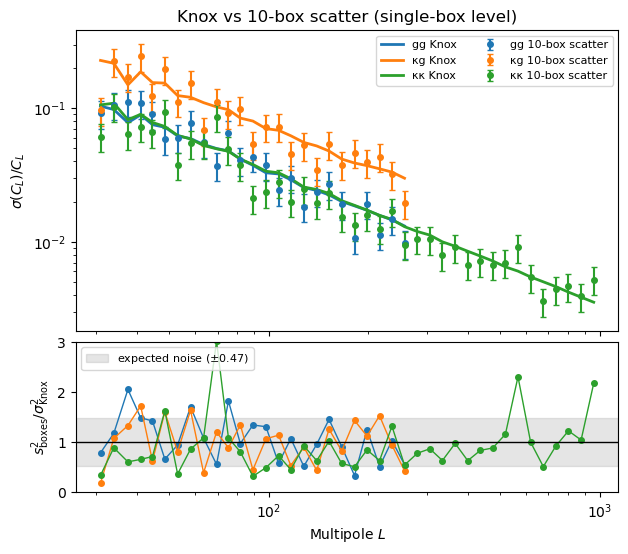

In [90]:
N = 10
specs = [('gg', cov_gg_fit*len(boxes), scatter_gg_data, cls_gg_data_binned, fit_mask,    'C0'),
         ('κg', cov_kg_fit*len(boxes), scatter_kg_data, cls_kg_data_binned, fit_mask,    'C1'),
         ('κκ', cov_kk_fit*len(boxes), scatter_kk_data, cls_kk_data_binned, fit_mask_kk, 'C2')]

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6),
                               gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.05})
for i, (name, cov, var_d, cl, m, c) in enumerate(specs):
    L = ells_binned[m]     # small offset so points don't overlap
    var_th = np.diag(cov)                            # single-box Knox (multiply by N if cov was /N)
    sig_th, sig_d = np.sqrt(var_th), np.sqrt(var_d[m])
    norm = np.abs(cl[m])
    ax1.plot(L, sig_th / norm, color=c, lw=2, label=f'{name} Knox')
    ax1.errorbar(L, sig_d / norm, yerr=sig_d / norm / np.sqrt(2 * (N - 1)),
                 fmt='o', ms=4, capsize=2, color=c, label=f'{name} {N}-box scatter')
    ax2.plot(L, var_d[m] / var_th, 'o-', ms=4, lw=1, color=c)

band = np.sqrt(2 / (N - 1))
ax2.axhspan(1 - band, 1 + band, color='grey', alpha=0.2, label=rf'expected noise ($\pm{band:.2f}$)')
ax2.axhline(1, color='k', lw=1)
ax1.set(xscale='log', yscale='log', ylabel=r'$\sigma(C_L)/C_L$')
ax2.set(xlabel='Multipole $L$', ylabel=r'$s^2_{\rm boxes}/\sigma^2_{\rm Knox}$', ylim=(0, 3))
ax1.legend(ncol=2, fontsize=8); ax2.legend(fontsize=8, loc='upper left')
ax1.set_title('Knox vs 10-box scatter (single-box level)')
plt.show()

## CMB lensing auto

### minimizer & sampler

In [91]:
# perform the chi2 minimization for kk data
bounds = [0.5, 1.5]  # bounds for sigma8
result_kk = minimize_scalar(
    get_chi2_single,
    bounds=bounds,
    method='bounded',
    args=(
        get_limber_cls_fit_kk,
        cls_kk_theory,
        B_pw_kk,
        fit_mask_kk,
        cls_kk_data_binned_fit,
        invcov_kk_fit,
        sigma8_fid,
        shot_noise
        )
)

# extract best-fit parameters, covariance and chi2
best_sigma8_kk  = result_kk.x
chi2_best_kk = result_kk.fun
reduced_chi2_best_kk = result_kk.fun/(nbins_fit_kk-1)  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_kk:.4f}")
print(f"Chi2/ndof: {chi2_best_kk:.2f}/{nbins_fit_kk-1} = {reduced_chi2_best_kk:.3f}")

Best-fit sigma8: 0.8240
Chi2/ndof: 69.57/39 = 1.784


In [92]:
# scipy best fit as starting point for MCMC
theta0_kk = result_kk.x

# initialize the MCMC
ndim_kk = 1
nwalkers_kk = 8 * ndim_kk  # number of walkers for MCMC, at least twice the number of dimensions

# small Gaussian scatter around the best-fit point
scatter_kk = theta0_kk * 0.03  # scatter for sigma8

# initialize walkers around best fit
start_kk = theta0_kk + scatter_kk * np.random.randn(nwalkers_kk, ndim_kk)

In [93]:
# initialize the kk sampler
sampler_kk = zeus.EnsembleSampler(
    nwalkers_kk,
    ndim_kk,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kk,
        cls_kk_theory,
        B_pw_kk,
        fit_mask_kk,
        cls_kk_data_binned_fit,
        invcov_kk_fit,
        sigma8_fid,
        shot_noise
        )
)

In [94]:
# define number of steps for MCMC
nsteps_kk = 5000

In [95]:
# run the kk MCMC
sampler_kk.run_mcmc(start_kk, nsteps_kk, progress=True)
sampler_kk.summary

Initialising ensemble of 8 walkers...
Sampling progress : 100%|██████████| 5000/5000 [00:08<00:00, 576.43it/s]
Summary
-------
Number of Generations: 5000
Number of Parameters: 1
Number of Walkers: 8
Number of Tuning Generations: 50
Scale Factor: 4.381187
Mean Integrated Autocorrelation Time: 1.01
Effective Sample Size: 39751.13
Number of Log Probability Evaluations: 264636
Effective Samples per Log Probability Evaluation: 0.150211


In [96]:
# save the kk chains to a file 
raw_chain_kk = sampler_kk.get_chain()

map_idx_kk = np.argmax(sampler_kk.get_log_prob(flat=True))
map_estimate_kk = sampler_kk.get_chain(flat=True)[map_idx_kk]
truths = np.array([1.0, sigma8_fid])

np.savez(f"../data/ensembles/chains/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz", 
         chain=raw_chain_kk, 
         nsteps=nsteps_kk, nwalkers=nwalkers_kk, ndim=ndim_kk, 
         lmin_fit=lmin_fit_kk, lmax_fit=lmax_fit_kk, nbins_fit=nbins_fit_kk,
         map_estimate=map_estimate_kk, bestfit_values=result_kk.x, true_values=truths[-1])

### deviation from the fiducial sigma8

In [97]:
chi2_fid_kk = get_chi2_single(
    sigma8_fid,
    get_limber_cls_fit_kk,
    cls_kk_theory,
    B_pw_kk,
    fit_mask_kk,
    cls_kk_data_binned_fit,
    invcov_kk_fit,
    sigma8_fid,
)

print(f"chi2 at fiducial sigma8 = {chi2_fid_kk:.3f}")
print(f"chi2 at best fit         = {chi2_best_kk:.3f}")
print(f"Delta chi2               = {chi2_fid_kk - chi2_best_kk:.3f}")

TypeError: get_chi2_single() missing 1 required positional argument: 'shot_noise'

In [ ]:
# Theory at the fiducial sigma8
cl_kk_fid = get_limber_cls_fit_kk(
    sigma8_fid,
    cls_kk_theory,
    sigma8_fid,
)

cl_kk_fid_binned = B_pw_kk @ cl_kk_fid

# Fractional residual per bandpower
fractional_residual = (
    cls_kk_data_binned - cl_kk_fid_binned
) / cl_kk_fid_binned

# Significance per bandpower using the current covariance
sigma_band = np.sqrt(np.diag(cov_kk_binned))
residual_sigma = (
    cls_kk_data_binned - cl_kk_fid_binned
) / sigma_band

print("Bin  ell         fractional residual   residual / sigma")
for i, (frac, sig) in enumerate(
    zip(fractional_residual, residual_sigma)
):
    print(f"{i:2d}   {(B @ ells)[i]:3f}   {frac:+.5f}             {sig:+.3f}")

In [ ]:
np.mean(residual_sigma)

### visualization

In [98]:
# load the chains from the file to visualize the results and clean the samples
nsteps_kk = 5000
lmax_fit_kk = 1000  # maximum multipole for fitting the CMB lensing auto spectrum

chain_filename_kk = f"../data/ensembles/chains/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz"
chain_file_kk = np.load(chain_filename_kk, allow_pickle=True)
chain_kk = chain_file_kk['chain']

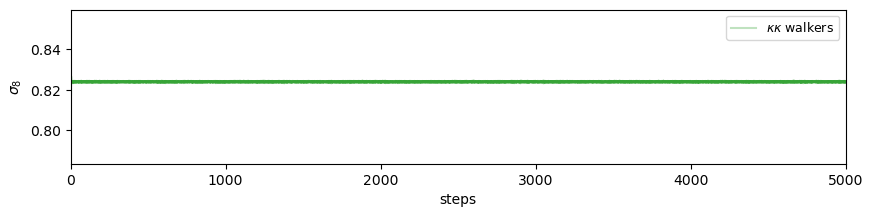

In [99]:
fig, ax = plt.subplots(1, figsize=(10, 2))

for walker in range(chain_kk.shape[1]):
    ax.plot(chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r"$\kappa \kappa$ walkers" if walker == 0 else "")
    ax.set_xlim(0, chain_kk.shape[0])
    ax.set_ylabel(r"$\sigma_8$")

ax.legend(loc='upper right', fontsize=9, frameon=True)
ax.set_xlabel('steps')

plt.show()

In [100]:
# declare the burnin and deleted walkers for each chain
burnin = 1000
deleted_walkers_kk = np.array([]).astype(int)  # indices of walkers to delete for kk

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain_kk = np.delete(chain_kk, obj=deleted_walkers_kk, axis=1) 
clean_chain_kk = clean_chain_kk[burnin:, : , :]
clean_samples_kk = clean_chain_kk.reshape(-1, clean_chain_kk.shape[-1])

# save the cleaned chains to a file
np.savez(chain_filename_kk, 
         chain=chain_kk, clean_samples=clean_samples_kk, 
         nsteps=chain_file_kk['nsteps'], burnin=burnin, nwalkers=chain_file_kk['nwalkers'], deleted_walkers=deleted_walkers_kk, ndim=chain_file_kk['ndim'], 
         lmin_fit=chain_file_kk['lmin_fit'], lmax_fit=chain_file_kk['lmax_fit'], nbins_fit=chain_file_kk['nbins_fit'],
         map_estimate=chain_file_kk['map_estimate'], bestfit_values=chain_file_kk['bestfit_values'], true_values=chain_file_kk['true_values'])

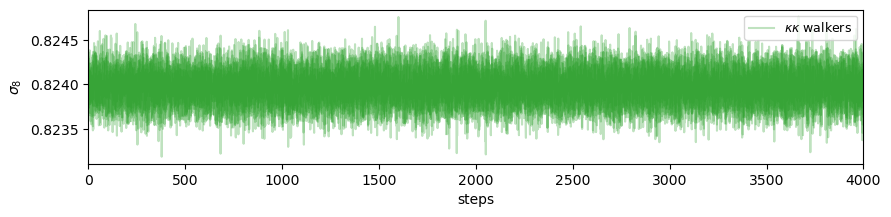

In [101]:
fig, ax = plt.subplots(1, figsize=(10, 2))
                  
for walker in range(clean_chain_kk.shape[1]):
    ax.plot(clean_chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r'$\kappa\kappa$ walkers' if walker == 0 else "")
    ax.set_xlim(0, clean_chain_kk.shape[0])
    ax.set_ylabel(r"$\sigma_8$")

ax.legend(loc='upper right', fontsize=9, frameon=True)
ax.set_xlabel('steps')

plt.show()

### marginalized constraints

In [102]:
# choose the box for which to compare the theory and the CoLoRe Cls
nsteps_kk = 5000 # number of steps for MCMC
lmax_fit_kk = 1000  # maximum multipole for kk fitting

In [103]:
# load the chains from the file 
chain_file_kk = np.load(f"../data/ensembles/chains/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz", allow_pickle=True)
# extract the chain and samples
samples_kk = chain_file_kk['clean_samples']

In [104]:
# extract the fitting parameters for the joint and single datasets
lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

Fitting parameters for the CMB lensing auto analysis:
lmin_fit: 30, lmax_fit: 1000, nbins_fit: 40


In [105]:
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

Removed no burn in


In [106]:
# get CMB lensing auto marginalized constraitns for sigma8
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly

sigma8_kk_mean = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err
N_sigma_kk = abs(sigma8_kk_mean - sigma8_fid) / sigma8_kk_err

print(f"sigma8 = {sigma8_kk_mean:.5f} +/- {sigma8_kk_err:.5f}")
print(f"sigma8 fiducial = {sigma8_fid:.5f}")
print(f"Distance = {N_sigma_kk:.2f} sigma")

sigma8 = 0.82397 +/- 0.00018
sigma8 fiducial = 0.82509
Distance = 6.04 sigma


## Joint dataset

### minimizer & sampler

In [ ]:
# perform the chi2 minimization
x0 = [1.0, sigma8_fid, 0.0]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5), (-5.0, 100.0)]  # bounds for Abias and sigma8
result = minimize(
    get_chi2,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(cls_theory,
        B_pw_gg,
        B_pw_kg,
        fit_mask,
        cls_data_binned_fit,
        invcov_fit,
        sigma8_fid,
        shot_noise
    )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_sigma8, best_Asn = result.x
chi2_best = result.fun
reduced_chi2_best = result.fun/(nbins_fit*2-len(result.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.4f}")
print(f"Best-fit A_bias: {best_Abias:.3f}")
print(f"Best-fit A_sn: {best_Asn:.3f}")
print(f"Chi2/ndof: {chi2_best:.2f}/({nbins_fit*2}-{len(result.x)}) = {reduced_chi2_best:.3f}")

In [ ]:
# scipy best fit as starting point for MCMC
theta0 = result.x

# initialize the MCMC
ndim = len(theta0)
nwalkers = 4 * ndim  # number of walkers for MCMC, at least twice the number of dimensions

# small Gaussian scatter around the best-fit point
scatter = theta0 * 0.05  # scatter

# initialize walkers around best fit
start = theta0 + scatter * np.random.randn(nwalkers, ndim)

In [ ]:
# initialize the sampler
sampler = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior,
    args=(
        cls_theory,
        B_pw_gg,
        B_pw_kg,
        fit_mask,
        cls_data_binned_fit,
        invcov_fit,
        sigma8_fid,
        shot_noise
    ),
)

# run the MCMC
nsteps = 50000
sampler.run_mcmc(start, nsteps, progress=True)
sampler.summary

In [ ]:
# save the chains to a file
raw_chain = sampler.get_chain()

map_idx = np.argmax(sampler.get_log_prob(flat=True))
map_estimate = sampler.get_chain(flat=True)[map_idx]
truths = np.array([np.nan, sigma8_fid, np.nan])

np.savez(f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}.npz", 
         chain=raw_chain, 
         nsteps=nsteps, 
         nwalkers=nwalkers, 
         ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit, 
         map_estimate=map_estimate, 
         bestfit_values=result.x, 
         true_values=truths)

### visualization

In [ ]:
# load the chains from the file to visualize the results and clean the samples
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps = 50000  # number of steps for MCMC
r_min = 50  # minimum scale for fitting in Mpc/h

chain_filename = f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}.npz"
chain_file = np.load(chain_filename, allow_pickle=True)

chain = chain_file['chain']
ndim = chain_file['ndim']

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 6), sharex=True)
axis_labels = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
    r"$A_{\rm sn}$"
]

for i in range(ndim):
    for walker in range(chain.shape[1]):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, len(chain))
    ax.set_ylabel(axis_labels[i])
axes[-1].set_xlabel('steps')
plt.show()

In [ ]:
chain[200, :, -1]

In [ ]:
# declare the burnin and deleted walkers for each chain
burnin = 1000
deleted_walkers = np.array([]).astype(int)  # indices of walkers to delete

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain = np.delete(chain, obj=deleted_walkers, axis=1)
clean_chain = clean_chain[burnin:, : , :]  # discard the first burnin steps
clean_samples = clean_chain.reshape(-1, clean_chain.shape[-1])  # reshape to 2D array for corner plot

# save the cleaned chains to a file
np.savez(chain_filename, 
         chain=chain_file['chain'], clean_samples=clean_samples, 
         nsteps=chain_file['nsteps'], burnin=burnin, 
         nwalkers=chain_file['nwalkers'], deleted_walkers=deleted_walkers, 
         ndim=chain_file['ndim'], 
         lmin_fit=chain_file['lmin_fit'], lmax_fit=chain_file['lmax_fit'], nbins_fit=chain_file['nbins_fit'], 
         map_estimate=chain_file['map_estimate'], 
         bestfit_values=chain_file['bestfit_values'], 
         true_values=chain_file['true_values'])

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 6), sharex=True)

for i in range(ndim):
    for walker in range(nwalkers-len(deleted_walkers)):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(clean_chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, clean_chain.shape[0])
    ax.set_ylabel(axis_labels[i])
axes[-1].set_xlabel('steps')
plt.show()

### plotter

In [ ]:
# choose the box for which to compare the theory and the CoLoRe Cls
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs_binx', 'desi_elg_binx', 'desi_lrg_binx', 'desi_qso_binx', 'lsst_gal_binx'

nsteps = 50000  # number of steps for MCMC
nsteps_single = nsteps  # number of steps for MCMC
nsteps_kk = 5000 # number of steps for MCMC

r_min = 50  # minimum scale for fitting in Mpc/h
lmax_fit_kk = 1000  # maximum multipole for kk fitting

In [ ]:
# load the chains from the file 
chain_file = np.load(f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}.npz", allow_pickle=True)
chain_file_gg = np.load(f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz", allow_pickle=True)
chain_file_kk = np.load(f"../data/ensembles/chains/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz", allow_pickle=True)

# extract the chain and samples
chain = chain_file['chain']
samples = chain_file['clean_samples']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']
samples_kk = chain_file_kk['clean_samples']

# extract the chain parameters
nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
deleted_walkers = chain_file['deleted_walkers']
burnin = chain_file['burnin']

# load the MAP estimate, best-fit values, and true values
map_estimate = chain_file['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

In [ ]:
# extract the fitting parameters for the joint and single datasets
lmin_fit = chain_file['lmin_fit']
lmax_fit = chain_file['lmax_fit']
nbins_fit = chain_file['nbins_fit']

lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the joint analysis:")
print(f"lmin_fit: {lmin_fit}, lmax_fit: {lmax_fit}, nbins_fit: {nbins_fit} \n")
print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

In [ ]:
# plot the chains for each parameter to inspect them
axis_labels = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
    r"$A_{\rm sn}$"
]

fig, axes = plt.subplots(int(ndim), figsize=(10, 6), sharex=True)

for i in range(ndim):
    for walker in np.delete(np.arange(nwalkers), deleted_walkers):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[burnin:, walker, i], alpha=0.5)
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

In [ ]:
# get the getdist samples for the joint analysis and the single analyses
cat_name = format_catalog_name(galaxy_catalog_bin)  # Format the galaxy string dynamically

names = ["Abias", "sigma8", "Asn"]
labels = [r"A_{\rm bias}", r"\sigma_8", r"A_{\rm sn}"]

legend_labels = [r"Joint Constraints ($g \times g$ + $\kappa \times g$)", 
    r"CMB lensing ($\kappa \times \kappa$)",
    rf"{cat_name} ($g \times g$)", 
    rf"CMB lensing $\times$ {cat_name} ($\kappa \times g$)"
]

samples_gd = MCSamples(samples=samples, names=names, labels=labels)
samples_gg_gd = MCSamples(samples=samples_gg, names=names, labels=labels)
samples_kg_gd = MCSamples(samples=samples_kg, names=names[0:2], labels=labels)
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

# reverse the order of the samples and colors for plotting
sample_list = [samples_gd, samples_kk_gd, samples_gg_gd, samples_kg_gd]
color_list = ["C0", "C4", "C1", "C2"]

sample_list_reversed = sample_list[::-1]
color_list_reversed = color_list[::-1]
legend_labels_reversed = legend_labels[::-1]

In [ ]:
# get the joint analysis marginalized statistics for sigma8
stats = samples_gd.getMargeStats()
sigma8_stats = stats.parWithName('sigma8')

sigma8_mean = sigma8_stats.mean
sigma8_err = sigma8_stats.err
N_sigma = abs(sigma8_mean - sigma8_fid) / sigma8_err

print(f"sigma8 = {sigma8_mean:.5f} +/- {sigma8_err:.5f}")
print(f"sigma8 fiducial = {sigma8_fid:.5f}")
print(f"Distance = {N_sigma:.2f} sigma")

In [ ]:
# get CMB lensing auto marginalized constraitns for sigma8
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly

sigma8_kk_mean = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err
N_sigma_kk = abs(sigma8_kk_mean - sigma8_fid) / sigma8_kk_err

print(f"sigma8 = {sigma8_kk_mean:.5f} +/- {sigma8_kk_err:.5f}")
print(f"sigma8 fiducial = {sigma8_fid:.5f}")
print(f"Distance = {N_sigma_kk:.2f} sigma")

In [ ]:
g = plots.get_subplot_plotter(subplot_size=3)
g.settings.legend_fontsize = 10
f_min = 0.90
f_max = 1.1
my_param_order = ['Abias', 'Asn', 'sigma8']

g.triangle_plot(sample_list_reversed,
                my_param_order,
                filled=True,
                title_limit=0,
                contour_colors=color_list_reversed,
                contour_lws=1.5,
                param_limits={'Abias': (map_estimate[0]*f_min, map_estimate[0]*f_max), 'sigma8': (map_estimate[1]*f_min, map_estimate[1]*f_max)})
g.add_param_markers({'sigma8': sigma8_fid}, color='red', ls='--', lw=1.5)

# change the order of the labels
g.fig.legends = [] 
g.add_legend(legend_labels=legend_labels_reversed, 
             figure=True,
             fontsize=12,
             bbox_to_anchor=(0.77, 0.99),
             label_order=[3, 1, 0, 2])  # <-- This flips the layout order inside the legend box!

# select the Abias-sigma8 subplot to add the MAP estimates and the fiducial value of sigma8, and CMB lensing auto constraints
ax = g.subplots[2, 0]
ax.scatter(map_estimate[0], map_estimate[1], color='cyan', marker="*", edgecolors='k', s=100, label="MAP Joint", zorder=5)
g.subplots[2, 0].legend(loc="upper right", fontsize=10, frameon=True)

ax.axhline(sigma8_kk_mean, color='C4', ls='-', lw=1.5)
g.add_y_bands(y=sigma8_kk_mean, sigma=sigma8_kk_err, color='C4', ax=g.subplots[2, 0], alpha1=0.4, alpha2=0.3)

# add titles to the subplots from the single analyses
title_Abias = samples_gd.getLatex('Abias', limit=1, err_sig_figs=2)
title_Asn = samples_gd.getLatex('Asn', limit=1, err_sig_figs=2)
title_sigma8 = samples_gd.getLatex('sigma8', limit=1, err_sig_figs=2)

title_fontsize = 11
g.subplots[0, 0].set_title(f"${title_Abias}$", fontsize=title_fontsize)
g.subplots[1, 1].set_title(f"${title_Asn}$", fontsize=title_fontsize)
g.subplots[2, 2].set_title(f"${title_sigma8}$", fontsize=title_fontsize)
g.subplots[2, 0].text(0.05, 0.07, rf"$\Delta \sigma_8^\mathrm{{joint}} =  {N_sigma:.2f}\sigma$"+"\n"
           +rf"$\Delta \sigma_8^\mathrm{{\kappa \kappa}} \ \ = {N_sigma_kk:.2f}\sigma$", transform=g.subplots[2, 0].transAxes, 
           fontsize=9, color='k', bbox=dict(facecolor='white', alpha=0.2, edgecolor='none'))

plot_filename = f"../data/ensembles/plots/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}_lmaxkk{lmax_fit_kk}"
plt.savefig(
    plot_filename + ".png",
    dpi=500,
    bbox_inches="tight")
plt.show()

## Single dataset

### minimizer-sampler

In [ ]:
# perform the chi2 minimization for gg data
x0 = [1.0, sigma8_fid, 0.0]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5), (-5.0, 100.0)]  # bounds for Abias and sigma8
result_gg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_gg,
        cls_gg_theory,
        B_pw_gg,
        fit_mask,
        cls_gg_data_binned_fit,
        invcov_gg_fit,
        sigma8_fid,
        shot_noise
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias_gg, best_sigma8_gg, best_Asn_gg = result_gg.x
chi2_best_gg = result_gg.fun
reduced_chi2_best_gg = result_gg.fun/(nbins_fit-len(result_gg.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_gg:.3f}")
print(f"Best-fit A_bias_gg: {best_Abias_gg:.3f}")
print(f"Best-fit A_sn_gg: {best_Asn_gg:.3f}")
print(f"Chi2/ndof: {chi2_best_gg:.2f}/{nbins_fit-len(result_gg.x)} = {reduced_chi2_best_gg:.3f}")

In [ ]:
# perform the chi2 minimization for kg data
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result_kg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_kg,
        cls_kg_theory,
        B_pw_kg,
        fit_mask,
        cls_kg_data_binned_fit,
        invcov_kg_fit,
        sigma8_fid,
        shot_noise
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias_kg, best_sigma8_kg  = result_kg.x
chi2_best_kg = result_kg.fun
reduced_chi2_best_kg = result_kg.fun/(nbins_fit-len(result_kg.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_kg:.3f}")
print(f"Best-fit A_bias_kg: {best_Abias_kg:.3f}")
print(f"Chi2/ndof: {chi2_best_kg:.2f}/{nbins_fit-len(result_kg.x)} = {reduced_chi2_best_kg:.3f}")

In [ ]:
# scipy best fit as starting point for MCMC
theta0_gg = result_gg.x
theta0_kg = result_kg.x

# initialize the MCMC
ndim_gg = len(theta0_gg)
ndim_kg = len(theta0_kg)
nwalkers_gg = 4 * ndim_gg   # number of walkers for MCMC, at least twice the number of dimensions
nwalkers_kg = 4 * ndim_kg 

# small Gaussian scatter around the best-fit point
scatter_gg = theta0_gg * 0.05  # scatter for Abias, sigma8 and A_sn
scatter_kg = theta0_kg * 0.05  # scatter for Abias, sigma8

# initialize walkers around best fit
start_gg = theta0_gg + scatter_gg * np.random.randn(nwalkers_gg, ndim_gg)
start_kg = theta0_kg + scatter_kg * np.random.randn(nwalkers_kg, ndim_kg)

In [ ]:
# initialize the gg sampler
sampler_gg = zeus.EnsembleSampler(
    nwalkers_gg,
    ndim_gg,
    log_posterior_single,
    args=(
        get_limber_cls_fit_gg,
        cls_gg_theory,
        B_pw_gg,
        fit_mask,
        cls_gg_data_binned_fit,
        invcov_gg_fit,
        sigma8_fid,
        shot_noise
        )
)

# initialize the kg sampler
sampler_kg = zeus.EnsembleSampler(
    nwalkers_kg,
    ndim_kg,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kg,
        cls_kg_theory,
        B_pw_kg,
        fit_mask,
        cls_kg_data_binned_fit,
        invcov_kg_fit,
        sigma8_fid,
        shot_noise
        )
)

In [ ]:
# define number of steps for MCMC
nsteps_single = 50000

In [ ]:
# run the gg MCMC
sampler_gg.run_mcmc(start_gg, nsteps_single, progress=True)
sampler_gg.summary

In [ ]:
# run the kg MCMC
sampler_kg.run_mcmc(start_kg, nsteps_single, progress=True)
sampler_kg.summary

In [ ]:
# save the gg/kg chains to a file 
raw_chain_gg = sampler_gg.get_chain()
raw_chain_kg = sampler_kg.get_chain()

map_idx_gg = np.argmax(sampler_gg.get_log_prob(flat=True))
map_estimate_gg = sampler_gg.get_chain(flat=True)[map_idx_gg]
map_idx_kg = np.argmax(sampler_kg.get_log_prob(flat=True))
map_estimate_kg = sampler_kg.get_chain(flat=True)[map_idx_kg]
truths_gg = np.array([np.nan, sigma8_fid, np.nan])
truths_kg = np.array([np.nan, sigma8_fid])

np.savez(f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz", 
         chain=raw_chain_gg, 
         nsteps=nsteps_single, 
         nwalkers=nwalkers_gg, 
         ndim=ndim_gg,
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_gg, 
         bestfit_values=result_gg.x, 
         true_values=truths_gg)
np.savez(f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz", 
         chain=raw_chain_kg, 
         nsteps=nsteps_single, 
         nwalkers=nwalkers_kg, 
         ndim=ndim_kg, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_kg, 
         bestfit_values=result_kg.x, 
         true_values=truths_kg)

### visualization

In [ ]:
# load the chains from the file to visualize the results and clean the samples
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 50000
nsteps_kk = 5000
r_min = 50  # minimum scale for fitting in Mpc/h
lmax_fit_kk = 1000  # maximum multipole for fitting the CMB lensing auto spectrum

chain_filename_gg = f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz"
chain_filename_kg = f"../data/ensembles/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz"
chain_filename_kk = f"../data/ensembles/chains/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz"
chain_file_gg = np.load(chain_filename_gg, allow_pickle=True)
chain_file_kg = np.load(chain_filename_kg, allow_pickle=True)
chain_file_kk = np.load(chain_filename_kk, allow_pickle=True)
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
chain_kk = chain_file_kk['chain']

ndim_gg = chain_file_gg['ndim']

In [ ]:
fig, axes = plt.subplots(int(ndim_gg+1), figsize=(10, 8))

axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
    r"$A_{\rm sn}$"
]

for i in range(ndim_gg):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker_gg, walker_kg in zip(range(chain_gg.shape[1]), range(chain_kg.shape[1])):
        ax.plot(chain_gg[:, walker_gg, i], c='C0', alpha=0.3, label="gg walkers" if walker_gg == 0 else "")
        if i < ndim_gg-1:  # last parameter is A_sn, which is not in kg chain
            ax.plot(chain_kg[:, walker_kg, i], c='C1', alpha=0.3, label=r"$\kappa$g walkers" if walker_kg == 0 else "")
    ax.set_xlim(0, len(chain_gg))
    ax.set_ylabel(axis_labels_single[i])

for walker in range(chain_kk.shape[1]):
    axes[-1].plot(chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r"$\kappa \kappa$ walkers" if walker == 0 else "")
    axes[-1].set_xlim(0, chain_kk.shape[0])
    axes[-1].set_ylabel(axis_labels_single[1])

axes[1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].set_xlabel('steps')

plt.show()

In [ ]:
# declare the burnin and deleted walkers for each chain
burnin = 10000
burnin_kk = 1000
deleted_walkers_gg = np.array([]).astype(int)  # indices of walkers to delete for gg
deleted_walkers_kg = np.array([]).astype(int)  # indices of walkers to delete for kg
deleted_walkers_kk = np.array([]).astype(int)  # indices of walkers to delete for kk

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain_gg = np.delete(chain_gg, obj=deleted_walkers_gg, axis=1)
clean_chain_kg = np.delete(chain_kg, obj=deleted_walkers_kg, axis=1)
clean_chain_kk = np.delete(chain_kk, obj=deleted_walkers_kk, axis=1) 
clean_chain_gg = clean_chain_gg[burnin:, : , :]  # discard the first burnin steps as burn-in
clean_chain_kg = clean_chain_kg[burnin:, : , :]
clean_chain_kk = clean_chain_kk[burnin_kk:, : , :]
clean_samples_gg = clean_chain_gg.reshape(-1, clean_chain_gg.shape[-1])  # reshape to 2D array for corner plot
clean_samples_kg = clean_chain_kg.reshape(-1, clean_chain_kg.shape[-1])
clean_samples_kk = clean_chain_kk.reshape(-1, clean_chain_kk.shape[-1])

# save the cleaned chains to a file
np.savez(chain_filename_gg, 
         chain=chain_file_gg['chain'], clean_samples=clean_samples_gg, 
         nsteps=chain_file_gg['nsteps'], burnin=burnin, 
         nwalkers=chain_file_gg['nwalkers'], deleted_walkers=deleted_walkers_gg, 
         ndim=chain_file_gg['ndim'], 
         lmin_fit=chain_file_gg['lmin_fit'], lmax_fit=chain_file_gg['lmax_fit'], nbins_fit=chain_file_gg['nbins_fit'],
         map_estimate=chain_file_gg['map_estimate'], 
         bestfit_values=chain_file_gg['bestfit_values'], 
         true_values=chain_file_gg['true_values'])
np.savez(chain_filename_kg, 
         chain=chain_file_kg['chain'], clean_samples=clean_samples_kg, 
         nsteps=chain_file_kg['nsteps'], burnin=burnin, 
         nwalkers=chain_file_kg['nwalkers'], deleted_walkers=deleted_walkers_kg, 
         ndim=chain_file_kg['ndim'], 
         lmin_fit=chain_file_kg['lmin_fit'], lmax_fit=chain_file_kg['lmax_fit'], nbins_fit=chain_file_kg['nbins_fit'],
         map_estimate=chain_file_kg['map_estimate'], 
         bestfit_values=chain_file_kg['bestfit_values'], 
         true_values=chain_file_kg['true_values'])
np.savez(chain_filename_kk, 
         chain=chain_file_kk['chain'], clean_samples=clean_samples_kk, 
         nsteps=chain_file_kk['nsteps'], burnin=burnin_kk, 
         nwalkers=chain_file_kk['nwalkers'], deleted_walkers=deleted_walkers_kk, 
         ndim=chain_file_kk['ndim'], 
         lmin_fit=chain_file_kk['lmin_fit'], lmax_fit=chain_file_kk['lmax_fit'], nbins_fit=chain_file_kk['nbins_fit'],
         map_estimate=chain_file_kk['map_estimate'], 
         bestfit_values=chain_file_kk['bestfit_values'], 
         true_values=chain_file_kk['true_values'])

In [ ]:
fig, axes = plt.subplots(int(ndim_gg+1), figsize=(10, 8))

for i in range(ndim_gg):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker_gg, walker_kg in zip(range(clean_chain_gg.shape[1]), range(clean_chain_kg.shape[1])):
        ax.plot(clean_chain_gg[:, walker_gg, i], c='C0', alpha=0.3, label='gg walkers' if walker_gg == 0 else "")
        if i < ndim_gg-1:  # last parameter is A_sn, which is not in kg chain
            ax.plot(clean_chain_kg[:, walker_kg, i], c='C1', alpha=0.3, label=r'$\kappa$g walkers' if walker_kg == 0 else "")
    ax.set_xlim(0, clean_chain_gg.shape[0])
    ax.set_ylabel(axis_labels_single[i])
                  
for walker in range(clean_chain_kk.shape[1]):
    axes[-1].plot(clean_chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r'$\kappa\kappa$ walkers' if walker == 0 else "")
    axes[-1].set_xlim(0, clean_chain_kk.shape[0])
    axes[-1].set_ylabel(axis_labels_single[1])

axes[1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].set_xlabel('steps')

plt.show()

### plotter: contours

In [ ]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_11'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'desi_qso_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 50000
nsteps_kk = 5000
r_min = 40  # minimum scale for fitting in Mpc/h
lmax_fit_kk = 1000  # maximum multipole for fitting the CMB lensing auto spectrum

# load the chains from the file 
chain_file_gg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz", allow_pickle=True)
chain_file_kk = np.load(f"../data/{box}/chains/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz", allow_pickle=True)

# extract the chain and samples
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
chain_kk = chain_file_kk['chain']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']
samples_kk = chain_file_kk['clean_samples']

# extract the chain parameters
nsteps_single = chain_file_gg['nsteps']
nwalkers_gg = chain_file_gg['nwalkers']
nwalkers_kg = chain_file_kg['nwalkers']
nwalkers_kk = chain_file_kk['nwalkers']
ndim_gg = chain_file_gg['ndim']
deleted_walkers_gg = chain_file_gg['deleted_walkers']
deleted_walkers_kg = chain_file_kg['deleted_walkers']
deleted_walkers_kk = chain_file_kk['deleted_walkers']
burnin = chain_file_gg['burnin']  # they should be equal, otherwise the uncertainty intervals comparison is not fair

# load the MAP estimate, best-fit values, and true values
map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
truths = chain_file_gg['true_values']

In [ ]:
# extract the fitting parameters for the gg/kg and kk single datasets
lmin_fit = chain_file_gg['lmin_fit']
lmax_fit = chain_file_gg['lmax_fit']
nbins_fit = chain_file_gg['nbins_fit']

lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the gg/kg analysis:")
print(f"lmin_fit: {lmin_fit}, lmax_fit: {lmax_fit}, nbins_fit: {nbins_fit}")
print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

In [ ]:
axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
    r"$A_{\rm sn}$"
]

fig, axes = plt.subplots(int(ndim_gg+1), figsize=(10, 8))
for i in range(ndim_gg):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker_gg, walker_kg in zip(np.delete(np.arange(nwalkers_gg), obj=deleted_walkers_gg, axis=0), np.delete(np.arange(nwalkers_kg), obj=deleted_walkers_kg, axis=0)):
        ax.plot(chain_gg[burnin:, walker_gg, i], c="C0", alpha=0.3, label="gg walkers" if walker_gg == 0 else "")
        if i < ndim_gg-1:  # last parameter is A_sn, which is not in kg chain
            ax.plot(chain_kg[burnin:, walker_kg, i], c="C1", alpha=0.3, label=r"$\kappa$g walkers" if walker_kg == 0 else "")
    ax.set_xlim(0, nsteps_single-burnin)
    ax.set_ylabel(axis_labels_single[i])

for walker in np.delete(np.arange(nwalkers_kk), obj=deleted_walkers_kk, axis=0):
    axes[-1].plot(chain_kk[burnin:, walker, -1], c="C2", alpha=0.3, label=r"$\kappa \kappa$ walkers" if walker == 0 else "")
    axes[-1].set_xlim(0, nsteps_kk-burnin)
    axes[-1].set_ylabel(axis_labels_single[1])

axes[1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].set_xlabel('steps')

plt.show()

In [ ]:
# get the getdist samples for the joint analysis and the single analyses
cat_name = format_catalog_name(galaxy_catalog_bin)  # Format the galaxy string dynamically

names = ["Abias", "sigma8", "Asn"]
labels = [r"A_{\rm bias}", r"\sigma_8", r"A_{\rm sn}"]

legend_labels = [
    rf"{cat_name} ($g \times g$)", 
    rf"CMB lensing $\times$ {cat_name} ($\kappa \times g$)", 
    r"CMB lensing ($\kappa \times \kappa$)"
]

samples_gg_gd = MCSamples(samples=samples_gg, names=names, labels=labels)
samples_kg_gd = MCSamples(samples=samples_kg, names=names[0:2], labels=labels)
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

In [ ]:
# get CMB lensing auto constraints
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly
sigma8_kk_mean = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err # This is the 1-sigma uncertainty

In [ ]:
# get the sample and color lists for plotting
sample_list = [samples_gg_gd, samples_kg_gd, samples_kk_gd]
color_list = ["C1", "C2", "C4"]

In [ ]:
g = plots.get_subplot_plotter(subplot_size=3)
f_min = 0.65
f_max = 1.35
my_param_order = ['Abias', 'Asn', 'sigma8']

g.triangle_plot(sample_list,
                my_param_order,
                filled=True,
                legend_labels=legend_labels,
                contour_colors=color_list,
                contour_lws=1.5,
                param_limits={'Abias': (f_min, f_max), 'sigma8': (truths[1]*f_min, truths[1]*f_max)})
g.add_param_markers({'sigma8': sigma8_fid}, color='red', ls='--', lw=1.5)

# select the Abias-sigma8 subplot to add the MAP estimates and the fiducial value of sigma8, and CMB lensing auto constraints
ax = g.subplots[2, 0]

ax.scatter(map_estimate_gg[0], map_estimate_gg[1], color='peachpuff', marker="*", edgecolors='k', s=100, label=r"MAP ($g \times g$)", zorder=5)
ax.scatter(map_estimate_kg[0], map_estimate_kg[1], color='lime', marker="*", edgecolors='k', s=100, label=r"MAP ($\kappa \times g$)", zorder=5)
#ax.axhline(truths[1], color="C3", ls="--", lw=1.5, zorder=4, label=r"$\sigma_8^{\mathrm{fid}}$")
ax.legend(loc="upper right", fontsize=10, frameon=True)

ax.axhline(sigma8_kk_mean, color='C4', ls='-', lw=1.5)
g.add_y_bands(y=sigma8_kk_mean, sigma=sigma8_kk_err, color='C4', ax=ax, alpha1=0.2, alpha2=0.2)

# add titles to the subplots from the single analyses
s0, s1, s2 = sample_list[0], sample_list[1], sample_list[2]

title_Abias_0 = s0.getInlineLatex('Abias', limit=1)
title_Abias_1 = s1.getInlineLatex('Abias', limit=1)

title_sigma8_0 = s0.getInlineLatex('sigma8', limit=1)
title_sigma8_1 = s1.getInlineLatex('sigma8', limit=1)
title_sigma8_2 = s2.getInlineLatex('sigma8', limit=1)

title_Asn_0 = s0.getInlineLatex('Asn', limit=1)

title_fontsize = 11
g.subplots[0, 0].set_title(
    f"{(r"$g \times g$")}: ${title_Abias_0}$\n{(r"$\kappa \times g$")}: ${title_Abias_1}$", 
    fontsize=title_fontsize)
g.subplots[2, 2].set_title(
    f"{(r"$g \times g$")}: ${title_sigma8_0}$\n{(r"$\kappa \times g$")}: ${title_sigma8_1}$\n{(r"$\kappa \times \kappa$")}: ${title_sigma8_2}$", 
    fontsize=title_fontsize)
g.subplots[1, 1].set_title(
    f"{(r"$g \times g$")}: ${title_Asn_0}$", 
    fontsize=title_fontsize)

plt.savefig(
    f"../data/{box}/plots/corner_plot_{galaxy_catalog_bin}_single_nsteps{nsteps_single}_rmin{r_min}_lmax{lmax_fit_kk}.png",
    dpi=500,
    bbox_inches="tight")
plt.show()

### plotter: cls

In [ ]:
cl_gg_lin, cl_kg_lin = get_limber_cls_fit([best_Abias, best_sigma8, best_Asn], cls_theory, sigma8_fid, shot_noise)

cl_gg_lin *= pixwin_gg**2
cl_kg_lin *= pixwin_kg
cl_gg_lin_binned = B @ cl_gg_lin
cl_kg_lin_binned = B @ cl_kg_lin

In [ ]:
plot_cls_comparison(ells, cl_gg_lin,
                    ells_binned, cls_gg_data_binned, np.sqrt(np.diag(cov_gg_binned)), cl_gg_lin_binned,
                       lmin_fit, lmax_fit, nbins_fit, best_sigma8, best_Abias, best_Asn,
                       box_label='ensembles', 
                       plot_title=f'{format_catalog_name(galaxy_catalog_bin)} auto-spectrum: \n Linear Theory vs. CoLoRe box \n($\\langle z \\rangle = {zmean:.2f}, \\ \\Delta z = {dz:.1f}$)',
                       test_name=f'{galaxy_catalog_bin}_joint_rmin{r_min}',
                       xx='gg')

plot_cls_comparison(ells, cl_kg_lin,
                    ells_binned, cls_kg_data_binned, np.sqrt(np.diag(cov_kg_binned)), cl_kg_lin_binned,
                       lmin_fit, lmax_fit, nbins_fit, best_sigma8, best_Abias, best_Asn,
                       box_label='ensembles',
                       plot_title=f'CMB Lensing $\\times$ {format_catalog_name(galaxy_catalog_bin)} cross-spectrum:\n Linear Theory vs. CoLoRe box \n ($\\langle z \\rangle = {zmean:.2f}, \\ \\Delta z = {dz:.1f}$)',
                       test_name=f'{galaxy_catalog_bin}_joint_rmin{r_min}',
                       xx='kg')

In [ ]:
cl_kk_lin = get_limber_cls_fit_kk(best_sigma8_kk, cls_kk_theory, sigma8_fid, shot_noise)
cl_kk_lin_binned = B @ cl_kk_lin

In [ ]:
plot_cls_comparison(ells, cl_kk_lin,
                    ells_binned, cls_kk_data_binned, np.sqrt(np.diag(cov_kk_binned)), cl_kk_lin_binned,
                       lmin_fit_kk, lmax_fit_kk, nbins_fit_kk, best_sigma8_kk, None, None,
                       box_label='ensembles',
                       plot_title=f'CMB Lensing auto-spectrum:\n Linear Theory vs. CoLoRe box',
                       test_name=f'lmax{lmax_fit_kk}',
                       xx='kk')